<a href="https://colab.research.google.com/github/ChanikyaMysur/MLA0403_DeepLearning/blob/main/Experiment_02_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Pandas Sample Covariance Matrix:
           Feature_1  Feature_2
Feature_1   2.099834   3.759817
Feature_2   3.759817   7.369413

NumPy Covariance Matrix:
[[2.09983442 3.75981673]
 [3.75981673 7.36941321]]

Eigenvalues: [9.32573882 0.14350881]
Eigenvectors (Columns):
 [[-0.46157947 -0.88709886]
 [-0.88709886  0.46157947]]


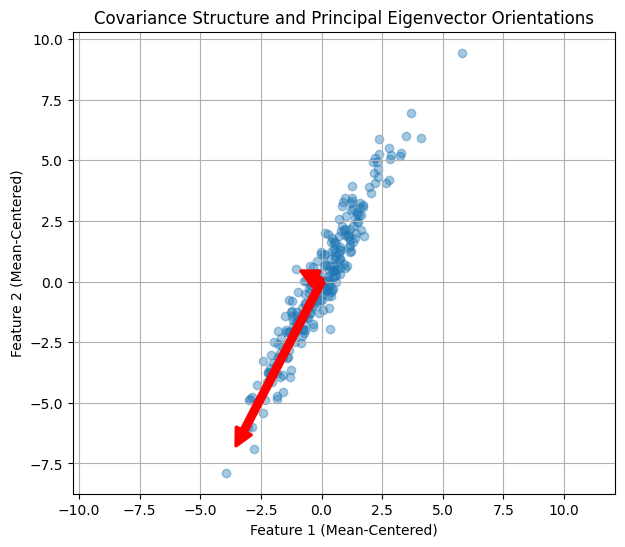

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Synthetic Correlated Dataset Generation
np.random.seed(42)
x = np.random.normal(loc=0, scale=1.5, size=250)
y = 1.8 * x + np.random.normal(loc=0, scale=0.8, size=250)

df = pd.DataFrame({'Feature_1': x, 'Feature_2': y})

# 2. Mean Centering & Covariance Analysis
df_centered = df - df.mean()
cov_matrix = np.cov(df_centered.T)

print("Pandas Sample Covariance Matrix:")
print(df.cov())
print("\nNumPy Covariance Matrix:")
print(cov_matrix)

# 3. Eigen-Decomposition
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

# Sort Eigenvalues/Eigenvectors descending
sort_indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sort_indices]
eigenvectors = eigenvectors[:, sort_indices]

print("\nEigenvalues:", eigenvalues)
print("Eigenvectors (Columns):\n", eigenvectors)

# 4. Plotting Data and Principal Axes (Eigenvectors)
plt.figure(figsize=(7, 6))
plt.scatter(df_centered['Feature_1'], df_centered['Feature_2'], alpha=0.4, label='Data Points')

# Draw Eigenvectors scaled by standard deviations (sqrt of Eigenvalues)
for eval_val, evec in zip(eigenvalues, eigenvectors.T):
    endpoint = evec * np.sqrt(eval_val) * 2.5
    plt.annotate('', xy=endpoint, xytext=(0, 0),
                 arrowprops=dict(facecolor='red', edgecolor='red', lw=2.5))

plt.xlabel('Feature 1 (Mean-Centered)')
plt.ylabel('Feature 2 (Mean-Centered)')
plt.title('Covariance Structure and Principal Eigenvector Orientations')
plt.grid(True)
plt.axis('equal')
plt.show()